# 정규화와 표준화 실습: 일곱 가지 데이터를 직접 열어 보기

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week01/feature_scaling/lab/feature_scaling.ipynb)

어떤 데이터든 순서는 같다. **① 열어서 모양 · 자료형 · 최솟값 · 최댓값을 본다 → ② 무엇마다 맞출지 정한다 → ③ 바꾼다 → ④ 바뀐 값을 다시 확인한다.**

- **파트 1**: 표 (와인 13성분): Min-Max · Z-score 직접 만들기, 그대로 72% vs 정규화 98% 재현
- **파트 2**: 흑백 이미지 (MNIST): uint8 함정, ÷255, 평균 · 표준편차
- **파트 3**: 컬러 이미지 (CIFAR-10): 채널(R, G, B)마다, 축 순서 (H, W, C) → (C, H, W)
- **파트 4**: 언어 (SMS 문자): 표기 맞추기, 단어 번호, 길이로 나누기
- **파트 5**: 시계열 (항공 승객): 학습 기간으로만 vs 창마다 표준화
- **파트 6**: 소리 (숫자 말소리): ÷32768, 음량 맞추기, dB 스펙트로그램
- **파트 7**: 비디오 (달리는 말): 프레임마다 vs 영상 전체

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 코드 칸 아래의 **예상 결과** 와 비교하면 맞았는지 바로 알 수 있습니다.

In [ ]:
import io, os, re, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageSequence
from scipy.io import wavfile
from scipy.signal import spectrogram

## 데이터 내려받기

일곱 가지 데이터를 `data/` 폴더에 받는다 (MNIST · CIFAR-10 때문에 처음엔 1~2분). 이미 받은 파일은 건너뛴다.

In [ ]:
FILES = {
    "c10_test.parquet": "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/test-00000-of-00001.parquet",
    "sms.zip": "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip",
    "air.csv": "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv",
    "horse.gif": "https://upload.wikimedia.org/wikipedia/commons/d/dd/Muybridge_race_horse_animated.gif",
}
SPEAKERS = ["jackson", "lucas", "george", "nicolas", "yweweler", "theo"]
for s in SPEAKERS:   # the digit 'zero' spoken by 6 people
    FILES[f"0_{s}_0.wav"] = f"https://raw.githubusercontent.com/Jakobovski/free-spoken-digit-dataset/master/recordings/0_{s}_0.wav"

os.makedirs("data", exist_ok=True)
for name, url in FILES.items():
    path = os.path.join("data", name)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course lab)"})
        with urllib.request.urlopen(req, timeout=120) as r, open(path, "wb") as f:
            f.write(r.read())
print(sorted(os.listdir("data")))

**예상 결과**

```
['0_george_0.wav', '0_jackson_0.wav', '0_lucas_0.wav', '0_nicolas_0.wav', '0_theo_0.wav', '0_yweweler_0.wav', 'MNIST', 'air.csv', 'c10_test.parquet', 'horse.gif', 'sms.zip']
```

## 데이터를 열어 보는 함수

파트마다 가장 먼저 이 함수로 **모양 · 자료형 · 최솟값 · 최댓값 · 평균 · 표준편차** 를 찍어 본다.

In [ ]:
def look(name, arr):
    """Print shape, dtype, min, max, mean, std of an array"""
    arr = np.asarray(arr)
    print(f"{name:14s} shape={str(arr.shape):18s} dtype={str(arr.dtype):8s} "
          f"min={arr.min():.4g}  max={arr.max():.4g}  mean={arr.mean():.4g}  std={arr.std():.4g}")

look("example", np.array([2, 4, 4, 4, 5, 5, 7, 9]))

**예상 결과**

```
example        shape=(8,)               dtype=int64    min=2  max=9  mean=5  std=2
```

## 파트 1. 표 데이터: 와인 13성분

와인 178병, 성분 13가지, 품종 3개. 성분마다(열마다) 범위가 얼마나 다른지 보자.

In [ ]:
from sklearn.datasets import load_wine
wine = load_wine(as_frame=True)
df = wine.data
print(df.shape)
df.describe().T[["min", "max", "mean", "std"]].round(2)

**예상 결과**

```
(178, 13)
                                 min      max    mean     std
alcohol                        11.03    14.83   13.00    0.81
malic_acid                      0.74     5.80    2.34    1.12
ash                             1.36     3.23    2.37    0.27
alcalinity_of_ash              10.60    30.00   19.49    3.34
magnesium                      70.00   162.00   99.74   14.28
total_phenols                   0.98     3.88    2.30    0.63
flavanoids                      0.34     5.08    2.03    1.00
nonflavanoid_phenols            0.13     0.66    0.36    0.12
proanthocyanins                 0.41     3.58    1.59    0.57
color_intensity                 1.28    13.00    5.06    2.32
hue                             0.48     1.71    0.96    0.23
od280/od315_of_diluted_wines    1.27     4.00    2.61    0.71
proline                       278.00  1680.00  746.89  314.91
```

**관찰**: `proline` 은 278 ~ 1,680, `hue` 는 0.48 ~ 1.71. 천 배 넘게 차이 난다.

두 함수를 만든다. 바꿀 값 `x` 와, 통계를 구할 데이터 `ref` 를 따로 받는다. 보통 `ref` 는 **학습 데이터**다.
- Min-Max: (x − min) ÷ (max − min)
- Z-score: (x − 평균) ÷ 표준편차 (`np.std`, n 으로 나눈다)

`axis=0` 으로 열마다 구하면 표 전체를 한 번에 바꿀 수 있다.

In [ ]:
def min_max(x, ref):
    """Scale x to 0~1 using min and max of ref (column by column)"""
    lo, hi = ref.min(axis=0), ref.max(axis=0)
    return None   # TODO: (x - min) / (max - min)

def z_score(x, ref):
    """Standardize x using mean and std of ref (column by column)"""
    return None   # TODO: (x - mean) / std

proline = df["proline"].values
print("wine #1 proline:", proline[0])
print("min-max:", round(min_max(proline, proline)[0], 2))   # slide: 0.56
print("z-score:", round(z_score(proline, proline)[0], 2))   # slide: 1.01

**예상 결과**

```
wine #1 proline: 1065.0
min-max: 0.56
z-score: 1.01
```

### 그대로 vs 정규화: 같은 신경망으로 비교

학습 70% · 시험 30% 로 나누고, **학습 데이터로만** 통계를 구해 두 쪽을 바꾼다. 신경망은 13 → 16 (tanh) → 3, Adam, 300번. 시드 10개 평균 (1분 안쪽).

In [ ]:
from sklearn.model_selection import train_test_split

def train_mlp(A, ya, B, yb, seed, steps=300):
    """Train a 13-16-3 tanh MLP on (A, ya). Returns (saturated fraction before training, test accuracy on (B, yb))"""
    torch.manual_seed(seed)
    net = torch.nn.Sequential(torch.nn.Linear(A.shape[1], 16), torch.nn.Tanh(), torch.nn.Linear(16, 3))
    A, B = torch.tensor(A, dtype=torch.float32), torch.tensor(B, dtype=torch.float32)
    ya, yb = torch.tensor(ya), torch.tensor(yb)
    with torch.no_grad():
        saturated = (net[1](net[0](A)).abs() > 0.99).float().mean().item()
    opt = torch.optim.Adam(net.parameters(), lr=0.01)
    for _ in range(steps):
        opt.zero_grad()
        torch.nn.functional.cross_entropy(net(A), ya).backward()
        opt.step()
    with torch.no_grad():
        acc = (net(B).argmax(1) == yb).float().mean().item()
    return saturated, acc

X, y = wine.data.values, wine.target.values
results = {"raw": [], "min-max": [], "z-score": []}
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
    inputs = {"raw": (Xtr, Xte),
              "min-max": (min_max(Xtr, Xtr), min_max(Xte, Xtr)),     # statistics from the training set only
              "z-score": (z_score(Xtr, Xtr), z_score(Xte, Xtr))}
    for name, (A, B) in inputs.items():
        results[name].append(train_mlp(A, ytr, B, yte, seed))
for name, r in results.items():
    sat, acc = np.mean(r, axis=0)
    print(f"{name:8s}: saturated neurons before training {sat:.0%}, test accuracy {acc:.0%}")

**예상 결과**

```
raw     : saturated neurons before training 98%, test accuracy 72%
min-max : saturated neurons before training 0%, test accuracy 98%
z-score : saturated neurons before training 0%, test accuracy 97%
```

**관찰**: 그대로 넣으면 학습 전 tanh 출력의 98% 가 ±1 에 붙어 있다 (기울기 0). 정규화하면 0%.

## 파트 2. 흑백 이미지: MNIST

손글씨 숫자 6만 장 (처음 실행하면 약 11MB 를 내려받는다). 열어서 자료형부터 보자.

In [ ]:
from torchvision import datasets
tr = datasets.MNIST("data", train=True, download=True)
te = datasets.MNIST("data", train=False, download=True)
X_train, y_train = tr.data.numpy(), tr.targets.numpy()
X_test, y_test = te.data.numpy(), te.targets.numpy()
look("MNIST train", X_train)
look("MNIST test", X_test)
plt.figure(figsize=(3, 3)); plt.imshow(X_train[0], cmap="gray"); plt.title(f"label {y_train[0]}"); plt.axis("off"); plt.show()

**예상 결과**

```
MNIST train    shape=(60000, 28, 28)    dtype=uint8    min=0  max=255  mean=33.32  std=78.57
MNIST test     shape=(10000, 28, 28)    dtype=uint8    min=0  max=255  mean=33.79  std=79.17
```

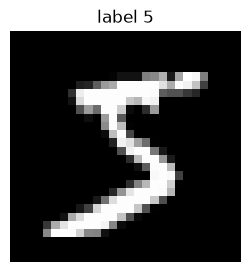

### uint8 함정

`uint8` 은 0 ~ 255 정수만 담는다. 픽셀에서 50 을 빼면 어떻게 될까?

In [ ]:
pixels = X_train[0, 14, 8:14]
print("pixels      :", pixels)
print("pixels - 50 :", pixels - np.uint8(50))      # values below 0 wrap around (0 - 50 -> 206)
print("as float    :", pixels.astype(np.float32) - 50)

**예상 결과**

```
pixels      : [ 0  0  0  0  0 81]
pixels - 50 : [206 206 206 206 206  31]
as float    : [-50. -50. -50. -50. -50.  31.]
```

**관찰**: 0 − 50 이 206 이 된다. 계산 전에 **반드시 실수형으로** 바꾼다. 아래 함수를 채우자: 실수형으로 바꾼 뒤 255 로 나눈다.

In [ ]:
def to_unit(images):
    """uint8 0~255 -> float32 0~1"""
    return None   # TODO: astype(float32), then / 255

X01 = to_unit(X_train)
look("MNIST / 255", X01)

**예상 결과**

```
MNIST / 255    shape=(60000, 28, 28)    dtype=float32  min=0  max=1  mean=0.1307  std=0.3081
```

흑백 이미지는 모든 픽셀이 같은 단위라 **이미지 전체에서 숫자 하나씩** 평균 · 표준편차를 구한다 (학습 6만 장으로).

In [ ]:
mean = None   # TODO: mean of all training pixels
std = None    # TODO: std of all training pixels
print(f"mean {mean:.4f}, std {std:.4f}")     # slide: 0.1307, 0.3081
look("MNIST z-score", (X01 - mean) / std)

**예상 결과**

```
mean 0.1307, std 0.3081
MNIST z-score  shape=(60000, 28, 28)    dtype=float32  min=-0.4241  max=2.822  mean=2.242e-08  std=1
```

### 그대로 vs ÷255 vs Z-score

학습 1만 장, 784 → 64 (tanh) → 10, SGD 0.1, 배치 100, 3에폭, 시험 1만 장. (슬라이드는 시드 3개 평균, 여기서는 1개)

In [ ]:
def train_digits(A, ya, B, yb, seed=0, epochs=3):
    """784-64-10 tanh MLP with SGD; returns (saturated fraction before training, test accuracy)"""
    torch.manual_seed(seed)
    net = torch.nn.Sequential(torch.nn.Linear(784, 64), torch.nn.Tanh(), torch.nn.Linear(64, 10))
    opt = torch.optim.SGD(net.parameters(), lr=0.1)
    A, B = torch.tensor(A.reshape(len(A), -1)), torch.tensor(B.reshape(len(B), -1))
    ya, yb = torch.tensor(ya), torch.tensor(yb)
    with torch.no_grad():
        saturated = (net[1](net[0](A)).abs() > 0.99).float().mean().item()
    for _ in range(epochs):
        perm = torch.randperm(len(A))
        for i in range(0, len(A), 100):
            idx = perm[i:i + 100]
            opt.zero_grad()
            torch.nn.functional.cross_entropy(net(A[idx]), ya[idx]).backward()
            opt.step()
    with torch.no_grad():
        acc = (net(B).argmax(1) == yb).float().mean().item()
    return saturated, acc

A_raw, B_raw = X_train[:10000].astype(np.float32), X_test.astype(np.float32)
for name, (A, B) in {"raw 0~255": (A_raw, B_raw),
                     "/ 255": (to_unit(X_train[:10000]), to_unit(X_test)),
                     "z-score": ((to_unit(X_train[:10000]) - mean) / std, (to_unit(X_test) - mean) / std)}.items():
    sat, acc = train_digits(A, y_train[:10000], B, y_test)
    print(f"{name:10s}: saturated {sat:.0%}, test accuracy {acc:.1%}")

**예상 결과**

```
raw 0~255 : saturated 95%, test accuracy 63.3%
/ 255     : saturated 0%, test accuracy 89.9%
z-score   : saturated 0%, test accuracy 92.1%
```

## 파트 3. 컬러 이미지: CIFAR-10

시험 이미지 1만 장 (비행기, 자동차, 새, 고양이 …). 한 픽셀에 R, G, B 세 값이 있다.

In [ ]:
cifar = pd.read_parquet("data/c10_test.parquet")
C = np.stack([np.array(Image.open(io.BytesIO(b["bytes"])).convert("RGB")) for b in cifar["img"]])
look("CIFAR-10", C)

img = C[23]
fig, axs = plt.subplots(1, 4, figsize=(10, 2.8))
axs[0].imshow(img); axs[0].set_title("RGB")
for k, name in enumerate(["R", "G", "B"]):
    axs[k + 1].imshow(img[..., k], cmap="gray", vmin=0, vmax=255); axs[k + 1].set_title(f"{name} channel")
for a in axs: a.axis("off")
plt.show()

**예상 결과**

```
CIFAR-10       shape=(10000, 32, 32, 3) dtype=uint8    min=0  max=255  mean=121.5  std=64.06
```

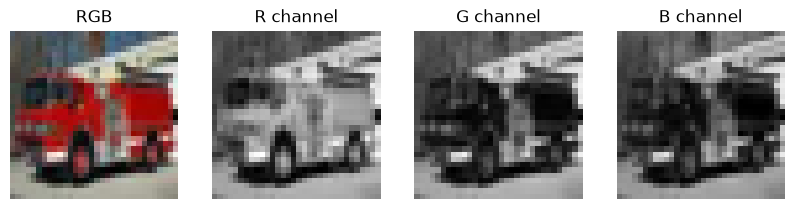

모양이 (장, 높이, 너비, 채널) 이다. 채널마다 숫자 하나씩, 즉 **숫자 3개** 가 나오도록 평균 · 표준편차를 구하자. 어느 축으로 평균을 내야 할까?

In [ ]:
C01 = C / 255      # float64
channel_mean = None   # TODO: mean over images, height, width -> 3 numbers
channel_std = None    # TODO: std over the same axes
print("mean (R, G, B):", channel_mean.round(3))    # slide: 0.494 0.485 0.450
print("std  (R, G, B):", channel_std.round(3))

**예상 결과**

```
mean (R, G, B): [0.494 0.485 0.45 ]
std  (R, G, B): [0.247 0.243 0.262]
```

In [ ]:
def normalize_channels(images01, mean, std):
    """(N, H, W, 3) float images -> per-channel z-score (mean, std are length-3 arrays)"""
    return None   # TODO: subtract mean, divide by std (broadcast over the last axis)

Cz = normalize_channels(C01, channel_mean, channel_std)
for k, name in enumerate(["R", "G", "B"]):
    look(f"channel {name}", Cz[..., k])

**예상 결과**

```
channel R      shape=(10000, 32, 32)    dtype=float64  min=-2.004  max=2.051  mean=-4.239e-12  std=1
channel G      shape=(10000, 32, 32)    dtype=float64  min=-1.997  max=2.12  mean=-8.087e-12  std=1
channel B      shape=(10000, 32, 32)    dtype=float64  min=-1.722  max=2.101  mean=-1.654e-11  std=1
```

### 축 순서: PyTorch 는 (N, C, H, W)

사진 파일은 (높이, 너비, 채널) 이지만 PyTorch 의 `Conv2d` 는 채널이 앞에 와야 한다. `transpose` 로 축을 옮기자.

In [ ]:
Ct = None   # TODO: (N, H, W, C) -> (N, C, H, W)
print("before:", Cz.shape, " after:", Ct.shape)

# Showing a normalized image directly gives wrong colors (values outside 0~1 are clipped). Undo it for display.
fig, axs = plt.subplots(1, 2, figsize=(5, 2.6))
axs[0].imshow(np.clip(Cz[23], 0, 1)); axs[0].set_title("normalized (clipped)")
axs[1].imshow(Cz[23] * channel_std + channel_mean); axs[1].set_title("undone for display")
for a in axs: a.axis("off")
plt.show()

**예상 결과**

```
before: (10000, 32, 32, 3)  after: (10000, 3, 32, 32)
```

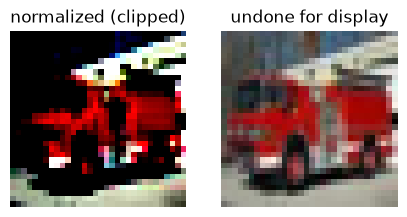

**참고**: 남이 학습시킨 모델 (예: torchvision 의 ImageNet 사전학습 모델) 을 쓸 때는 그 모델이 학습할 때 쓴 값 `mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]` 을 그대로 쓴다.

## 파트 4. 언어: SMS 문자 5,574통

언어는 숫자 크기가 아니라 **표기** 를 맞춘다.

In [ ]:
with zipfile.ZipFile("data/sms.zip") as z:
    df = pd.read_csv(z.open("SMSSpamCollection"), sep="\t", names=["label", "text"], quoting=3)
print(df.shape)
print(df.text.head(3).tolist())
lengths = df.text.str.split().str.len()
look("words/message", lengths)

**예상 결과**

```
(5574, 2)
['Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...', 'Ok lar... Joking wif u oni...', "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"]
words/message  shape=(5574,)            dtype=int64    min=1  max=171  mean=15.59  std=11.39
```

In [ ]:
raw_words = " ".join(df.text).split()
print("word types, just split by spaces:", len(set(raw_words)))
print([w for w in set(raw_words) if w.lower().strip("!.,?") == "free"])

**예상 결과**

```
word types, just split by spaces: 15733
['FREE!', 'free,', 'free', 'free?', 'Free,', 'Free', 'free...', 'FREE', 'FREE.', 'free.', 'Free!', 'free!', 'free..']
```

`FREE`, `Free`, `free!` 가 모두 다른 단어로 잡힌다. 소문자로 바꾸고, 글자 · 숫자가 2개 이상 이어진 덩어리만 단어로 뽑는 함수를 만들자 (힌트: `re.findall(r"\b\w\w+\b", ...)`).

In [ ]:
def normalize_text(text):
    """Lowercase, then keep runs of 2+ letters/digits as words"""
    return None   # TODO: lowercase + re.findall(r"\b\w\w+\b", ...)

print(normalize_text("FREE entry!! Call 08452810075 now, Free free!"))
docs = [normalize_text(t) for t in df.text]
vocab = sorted({w for d in docs for w in d})
print("word types after normalizing:", len(vocab))     # slide: 15,733 -> 8,713

**예상 결과**

```
['free', 'entry', 'call', '08452810075', 'now', 'free', 'free']
word types after normalizing: 8713
```

### 단어 번호는 크기가 아니다

단어마다 번호(id) 를 붙인다. `free` 가 `call` 보다 번호가 크다고 '더 큰' 단어일까? 번호는 이름표라서 표준화하지 않고, 학습할 벡터(임베딩) 로 바꾼다.

In [ ]:
word_id = {w: i for i, w in enumerate(vocab)}
print("free ->", word_id["free"], "  call ->", word_id["call"], "  win ->", word_id["win"])

emb = torch.nn.Embedding(len(vocab), 16)       # one learnable 16-dim vector per word id
look("embedding init", emb.weight.detach().numpy())   # already mean 0, std 1

**예상 결과**

```
free -> 3373   call -> 1828   win -> 8463
embedding init shape=(8713, 16)         dtype=float32  min=-4.348  max=4.082  mean=-0.002422  std=1.003
```

### 단어 세기는 길이로 나누기

문자 하나를 '단어가 몇 번 나왔나' 벡터로 만들면, 긴 문자일수록 숫자가 커진다. 단어 수로 나눠 **비율** 로 바꾸는 함수를 만들자.

In [ ]:
def count_vector(words, word_id):
    """How many times each vocabulary word appears"""
    v = np.zeros(len(word_id))
    for w in words:
        if w in word_id:
            v[word_id[w]] += 1
    return v

def frequency_vector(words, word_id):
    """Counts divided by the number of words (sums to 1)"""
    return None   # TODO: count_vector / number of words

short, long_ = normalize_text("call me now"), normalize_text("call me now " * 5)
for name, w in [("short", short), ("5x longer", long_)]:
    c, f = count_vector(w, word_id), frequency_vector(w, word_id)
    print(f"{name:10s} count of 'call' = {c[word_id['call']]:.0f}, frequency of 'call' = {f[word_id['call']]:.2f}")

**예상 결과**

```
short      count of 'call' = 1, frequency of 'call' = 0.33
5x longer  count of 'call' = 5, frequency of 'call' = 0.33
```

## 파트 5. 시계열: 국제선 항공 승객 1949~1960

한 달 승객 수 (천 명). 앞 10년 (120달) 으로 학습, 뒤 2년을 예측한다. **과거만 보고** 정규화해야 한다.

In [ ]:
air = pd.read_csv("data/air.csv")
series = air["Passengers"].values.astype(float)
N_TRAIN = 120
look("train 1949-58", series[:N_TRAIN])
look("test 1959-60", series[N_TRAIN:])
plt.figure(figsize=(8, 3)); plt.plot(series); plt.axvline(N_TRAIN, color="gray", ls=":")
plt.xlabel("month"); plt.ylabel("passengers (1000s)"); plt.show()

**예상 결과**

```
train 1949-58  shape=(120,)             dtype=float64  min=104  max=505  mean=245.9  std=94.55
test 1959-60   shape=(24,)              dtype=float64  min=342  max=622  mean=452.2  std=74.68
```

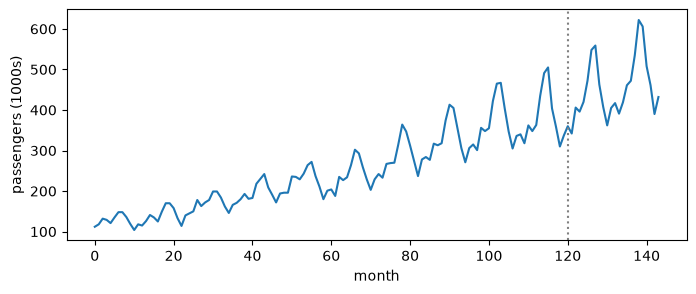

**관찰**: 시험 기간 최댓값 622 는 학습 기간 최댓값 505 보다 크다. 학습 기간의 min · max 로 Min-Max 하면 1 을 넘는다.

'지난 12달 → 다음 달' 문제로 바꾸는 함수를 만든다. `X[i]` = `series[i : i+12]`, `y[i]` = `series[i+12]`.

In [ ]:
def make_windows(series, w):
    """Rows of w past values (X) and the next value (y)"""
    X = None   # TODO: stack series[i:i+w] for each i
    y = series[w:]
    return X, y

W = 12
Xw, yw = make_windows(series, W)
is_train = np.arange(W, len(series)) < N_TRAIN     # the predicted month is in 1949-58
print(Xw.shape, yw.shape, "train rows:", is_train.sum(), "test rows:", (~is_train).sum())
print("min-max of the test max with train min/max:", round((series[N_TRAIN:].max() - series[:N_TRAIN].min()) / (series[:N_TRAIN].max() - series[:N_TRAIN].min()), 2))

**예상 결과**

```
(132, 12) (132,) train rows: 108 test rows: 24
min-max of the test max with train min/max: 1.29
```

### 방법 A: 학습 기간 전체의 평균 · 표준편차로

k-최근접 이웃 (k = 3) 은 학습 때 본 비슷한 12달을 찾아 그 다음 달을 평균 낸다.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

mu, sd = series[:N_TRAIN].mean(), series[:N_TRAIN].std()
knn = KNeighborsRegressor(3).fit((Xw[is_train] - mu) / sd, (yw[is_train] - mu) / sd)
pred_global = knn.predict((Xw[~is_train] - mu) / sd) * sd + mu        # back to passengers
mae_global = np.abs(pred_global - yw[~is_train]).mean()
print(f"MAE {mae_global:.0f}k passengers, largest prediction {pred_global.max():.0f}")

**예상 결과**

```
MAE 74k passengers, largest prediction 487
```

**관찰**: 가장 큰 예측이 학습 기간 최대 505 를 넘지 못한다. 본 적 없는 크기는 내놓지 못한다.

### 방법 B: 창(12달) 마다 그 창의 평균 · 표준편차로

각 행을 자기 평균 · 표준편차로 표준화하면, 모델은 크기가 아니라 **모양** 을 배운다. 예측한 뒤 그 창의 값으로 되돌린다.

In [ ]:
def window_zscore(X):
    """Standardize each row with its own mean and std. Returns (Z, mean, std), mean and std have shape (rows, 1)"""
    m = None   # TODO: mean of each row, keepdims=True
    s = None   # TODO: std of each row, keepdims=True
    return (X - m) / s, m, s

Z, m, s = window_zscore(Xw)
target = (yw - m[:, 0]) / s[:, 0]             # next month in units of its window
knn = KNeighborsRegressor(3).fit(Z[is_train], target[is_train])
pred_window = knn.predict(Z[~is_train]) * s[~is_train, 0] + m[~is_train, 0]
mae_window = np.abs(pred_window - yw[~is_train]).mean()
print(f"MAE: whole train period {mae_global:.0f}k  ->  per window {mae_window:.0f}k")    # slide: 74 -> 10

months = np.arange(len(series))
plt.figure(figsize=(9, 3.4))
plt.plot(months, series, color="black", label="actual")
plt.plot(months[N_TRAIN:], pred_global, "r--", label=f"whole train period (MAE {mae_global:.0f})")
plt.plot(months[N_TRAIN:], pred_window, "g--", label=f"per window (MAE {mae_window:.0f})")
plt.axvline(N_TRAIN, color="gray", ls=":"); plt.legend(); plt.xlabel("month"); plt.show()

**예상 결과**

```
MAE: whole train period 74k  ->  per window 10k
```

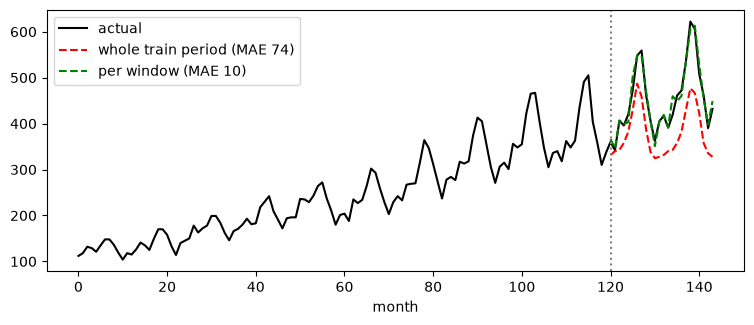

## 파트 6. 소리: 숫자 'zero' 를 말한 6명

`.wav` 파일은 1초에 8,000번 잰 숫자의 줄이다. 자료형과 범위부터 보자.

In [ ]:
waves = {}
for s in SPEAKERS:
    rate, w = wavfile.read(f"data/0_{s}_0.wav")
    waves[s] = w
    look(s, w)
print("sample rate:", rate)

**예상 결과**

```
jackson        shape=(5148,)            dtype=int16    min=-2.166e+04  max=2.416e+04  mean=-0.2374  std=4482
lucas          shape=(5083,)            dtype=int16    min=-1.091e+04  max=6586  mean=-0.6545  std=1767
george         shape=(2384,)            dtype=int16    min=-9165  max=1.035e+04  mean=1.802  std=2912
nicolas        shape=(3500,)            dtype=int16    min=-7424  max=5632  mean=-252.2  std=1871
yweweler       shape=(3103,)            dtype=int16    min=-1757  max=1296  mean=-0.7293  std=374
theo           shape=(3142,)            dtype=int16    min=-606  max=655  mean=-0.2772  std=177
sample rate: 8000
```

`int16` 은 −32768 ~ 32767. 32768 로 나눠 −1 ~ 1 로 바꾸고, 녹음마다 가장 큰 소리 (피크) 를 보자. (들어 보려면 `from IPython.display import Audio; Audio(w, rate=rate)`)

In [ ]:
def to_float(wave):
    """int16 -> float -1~1"""
    return None   # TODO: astype(float32) / 32768

for s in SPEAKERS:
    print(f"{s:9s} peak = {np.abs(to_float(waves[s])).max():.2f}")
print("loudest / quietest:", round(np.abs(to_float(waves['jackson'])).max() / np.abs(to_float(waves['theo'])).max()))

**예상 결과**

```
jackson   peak = 0.74
lucas     peak = 0.33
george    peak = 0.32
nicolas   peak = 0.23
yweweler  peak = 0.05
theo      peak = 0.02
loudest / quietest: 37
```

같은 말인데 음량이 37배 다르다. 녹음마다 가장 큰 값으로 나누는 **피크 정규화** 를 만들자.

In [ ]:
def peak_normalize(wave):
    """Divide by the largest absolute value -> peak becomes 1"""
    return None   # TODO: wave / largest |value|

fig, axs = plt.subplots(2, 2, figsize=(10, 4), sharey=True)
for col, s in enumerate(["jackson", "theo"]):
    w = to_float(waves[s])
    axs[0, col].plot(w, lw=0.5); axs[0, col].set_title(f"{s}: / 32768")
    axs[1, col].plot(peak_normalize(w), lw=0.5, color="teal"); axs[1, col].set_title(f"{s}: peak normalized")
plt.tight_layout(); plt.show()
for s in ["jackson", "theo"]:
    print(s, "peak after:", np.abs(peak_normalize(to_float(waves[s]))).max())

**예상 결과**

```
jackson peak after: 1.0
theo peak after: 1.0
```

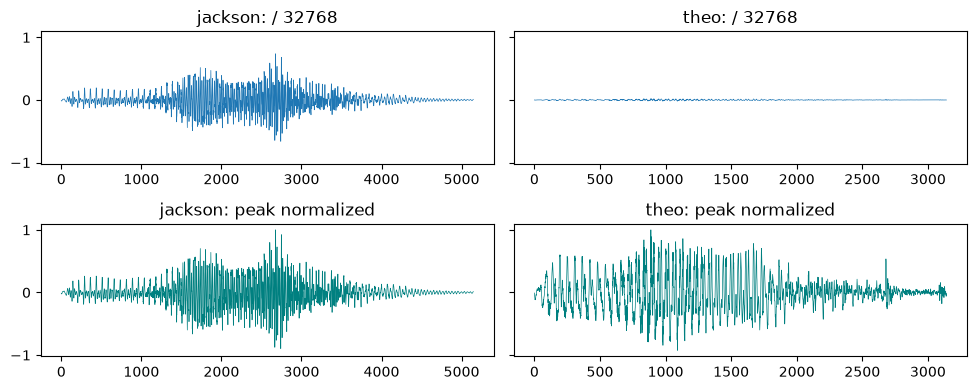

### 스펙트로그램: 로그(dB) 로 본다

시간마다 어느 주파수에 에너지가 있는지 그린 그림. 값의 범위가 엄청나게 넓어서 그대로 그리면 거의 까맣다. `10 · log10` 으로 데시벨(dB) 로 바꾸자 (0 을 피하려고 아주 작은 수 `1e-10` 을 더한다).

In [ ]:
f, t, S = spectrogram(to_float(waves["jackson"]), fs=rate, nperseg=256, noverlap=192)
look("energy", S)
S_db = None   # TODO: 10 * log10(S + 1e-10)
look("energy (dB)", S_db)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].pcolormesh(t, f, S, shading="auto", cmap="magma"); axs[0].set_title("energy as is")
axs[1].pcolormesh(t, f, S_db, shading="auto", cmap="magma", vmin=S_db.max() - 80); axs[1].set_title("10 log10 (dB)")
for a in axs: a.set_xlabel("time (s)"); a.set_ylabel("Hz")
plt.tight_layout(); plt.show()

**예상 결과**

```
energy         shape=(129, 77)          dtype=float32  min=1.483e-14  max=0.001452  mean=4.805e-06  std=4.802e-05
energy (dB)    shape=(129, 77)          dtype=float32  min=-100  max=-28.38  mean=-78.61  std=15.64
```

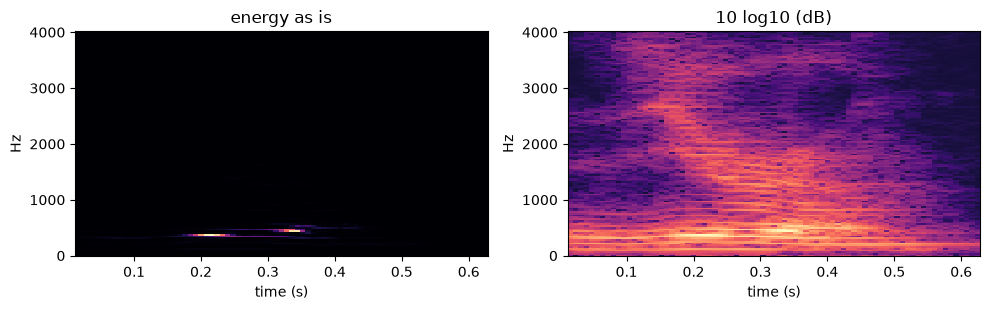

## 파트 7. 비디오: 달리는 말 (Muybridge, 1878)

비디오 = 이미지를 시간 순서로 쌓은 것. GIF 의 프레임을 읽어 (T, H, W, C) 배열로 만든다.

In [ ]:
gif = Image.open("data/horse.gif")
video = np.stack([np.array(frame.convert("RGB")) for frame in ImageSequence.Iterator(gif)])
look("video", video)

fig, axs = plt.subplots(1, 5, figsize=(12, 2))
for a, i in zip(axs, [0, 3, 6, 9, 12]):
    a.imshow(video[i]); a.set_title(f"frame {i}"); a.axis("off")
plt.show()

**예상 결과**

```
video          shape=(15, 200, 300, 3)  dtype=uint8    min=0  max=245  mean=177.4  std=68.08
```

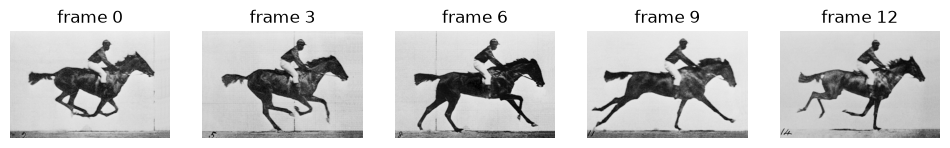

해가 지듯 **점점 어두워지는** 영상을 일부러 만든다 (프레임 0 은 밝기 1배, 마지막은 0.25배). 이 변화가 정규화 뒤에도 남을까?

In [ ]:
fade = np.linspace(1, 0.25, len(video)).reshape(-1, 1, 1, 1)
dark = video.astype(np.float32) / 255 * fade
print("frame brightness:", dark.mean(axis=(1, 2, 3)).round(2))

**예상 결과**

```
frame brightness: [0.73 0.67 0.63 0.57 0.54 0.51 0.45 0.43 0.4  0.37 0.33 0.29 0.24 0.21
 0.17]
```

두 가지로 표준화해 본다.
- `per_frame_z`: 프레임마다 자기 평균 · 표준편차로 (`axis=(1, 2, 3)`, `keepdims=True`)
- `per_clip_z`: 영상 전체의 평균 · 표준편차 하나로

In [ ]:
def per_frame_z(video):
    """Standardize every frame with its own mean and std"""
    m = None   # TODO: mean of each frame (axis=(1, 2, 3), keepdims=True)
    s = None   # TODO: std of each frame
    return (video - m) / s

def per_clip_z(video):
    """Standardize the whole clip with one mean and std"""
    return None   # TODO: one mean and std for the whole clip

for name, v in [("per frame", per_frame_z(dark)), ("whole clip", per_clip_z(dark))]:
    print(f"{name:10s} frame means:", v.mean(axis=(1, 2, 3)).round(2))

fig, axs = plt.subplots(3, 5, figsize=(12, 5))
for r, (name, v, lim) in enumerate([("darkening", dark, (0, 1)), ("per frame", per_frame_z(dark), (-2.5, 2)),
                                    ("whole clip", per_clip_z(dark), (-2.5, 2))]):
    for c, i in enumerate([0, 3, 6, 9, 12]):
        axs[r, c].imshow(v[i, ..., 0], cmap="gray", vmin=lim[0], vmax=lim[1]); axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
    axs[r, 0].set_ylabel(name)
plt.tight_layout(); plt.show()

**예상 결과**

```
per frame  frame means: [ 0.  0. -0. -0.  0. -0. -0. -0.  0.  0. -0.  0.  0. -0. -0.]
whole clip frame means: [ 1.2   0.97  0.79  0.56  0.42  0.29  0.06 -0.03 -0.13 -0.28 -0.45 -0.59
 -0.78 -0.93 -1.1 ]
```

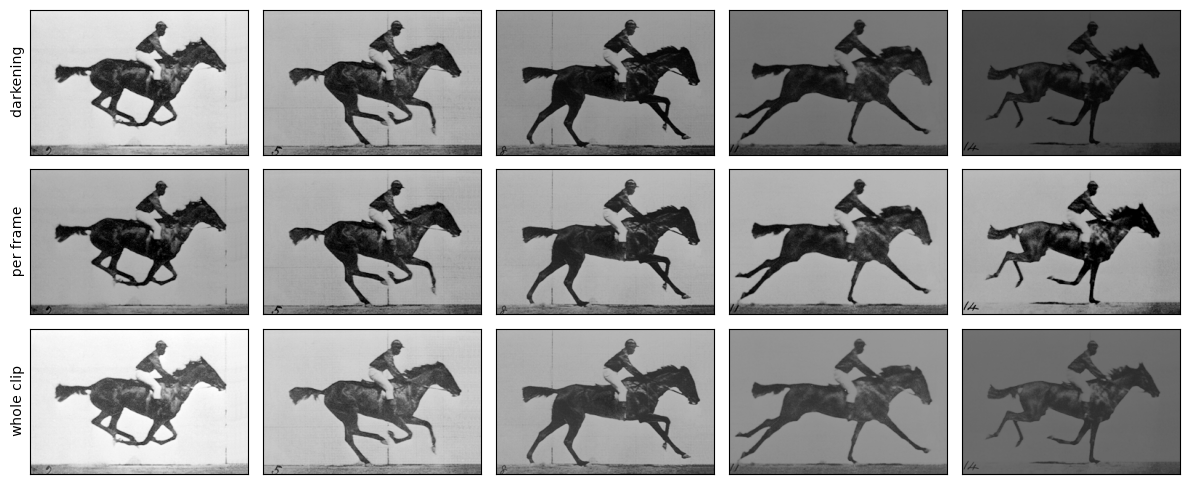

**관찰**: 프레임마다 표준화하면 모든 프레임의 평균이 0 이 되어 어두워지는 변화가 사라진다. 영상 전체로 하면 남는다.

마지막으로 PyTorch 의 `Conv3d` 는 (C, T, H, W) 순서를 쓴다. 축을 옮기자.

In [ ]:
clip = None   # TODO: (T, H, W, C) -> (C, T, H, W)
print("before:", dark.shape, " after:", clip.shape)

**예상 결과**

```
before: (15, 200, 300, 3)  after: (3, 15, 200, 300)
```

**확인 질문**
1. 파트 1 에서 시험 데이터의 통계로 `z_score(Xte, Xte)` 를 하면 무엇이 문제일까? 실제 서비스에서 데이터가 한 개씩 들어온다면?
2. 파트 2 에서 `X_train - mean` 을 uint8 그대로 계산하면 어떤 일이 생길까?
3. 파트 3 에서 `axis=(0, 1, 2)` 대신 `axis=None` 으로 평균을 내면 숫자 몇 개가 나오나? 그게 왜 부족할까?
4. 파트 4 에서 단어 번호 `word_id` 를 Z-score 로 바꿔 모델에 넣으면 모델은 무엇을 배우게 될까?
5. 파트 5 의 방법 B 가 방법 A 보다 나은 이유를 '크기' 와 '모양' 이라는 말로 설명해 보자.
6. 파트 7 에서 프레임마다 표준화하는 편이 오히려 좋은 문제는? (힌트: 조명이 계속 바뀌는 CCTV 에서 사람 찾기)

데이터 출처: UCI Wine (Aeberhard & Forina, 1991) · MNIST (LeCun, Cortes, Burges) · CIFAR-10 (Krizhevsky, 2009) · UCI SMS Spam Collection (Almeida & Hidalgo, 2011) · Box & Jenkins (1976) 항공 승객 · Free Spoken Digit Dataset (Jackson 외, CC BY-SA 4.0) · Muybridge, The Horse in Motion (1878, 퍼블릭 도메인).